# Task 1 — Diagnóstico, baselines e ARIMA/SARIMA

Séries diárias da loja M5 `CA_1` (`store_total`, `FOODS`, `HOBBIES`). Este notebook é a fonte da análise e das justificativas da Task 1; o pipeline que gera os entregáveis (`metricas.csv`, `previsoes_validacao.csv`, `figuras/`) é o `run.py`, que usa as mesmas funções (`src/ts_utils.py`) e as mesmas ordens de SARIMA.

**Como usar:** rode `python run.py` na raiz e depois execute este notebook de cima para baixo. As células de conferência comparam o resultado do notebook com o `metricas.csv`.

**Regra anti-vazamento:** modelos e decisões de modelagem usam apenas o **treino** (2011-01-29 a 2016-03-27). A validação (2016-03-28 a 2016-04-24, 28 dias) só é usada para calcular o erro das previsões já geradas.

**Roteiro**
1. Diagnóstico: série, tendência, sazonalidade, outliers, ACF/PACF e testes de raiz unitária.
2. Baselines: média, naive, naive sazonal (m=7) e drift.
3. SARIMA: identificação da ordem, ajuste, resíduos, previsão e comparação com os baselines.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve()  # rode o notebook a partir da raiz do repo
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ts_utils import BASELINES, M, SERIES, calcular_baselines, calcular_metricas, carregar_dados

import run  # funções do pipeline (identificar_sarima, prever_sarima); run.main() não roda no import
%matplotlib inline
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss

treino, val = carregar_dados(RAIZ)
h = len(val)
df_train, df_val = treino.copy(), val.copy()  # df_* são usados na Parte 1
print(f"Treino: {treino.date.min().date()} a {treino.date.max().date()} ({len(treino)} dias)")
print(f"Validação: {val.date.min().date()} a {val.date.max().date()} ({h} dias)")

Treino: 2011-01-29 a 2016-03-27 (1885 dias)
Validação: 2016-03-28 a 2016-04-24 (28 dias)


O treino tem 1885 dias e a validação, 28. Os arquivos já vêm separados no tempo; não há embaralhamento nem mistura entre eles.

# Parte 1 — Diagnóstico das séries (treino)

### Colunas derivadas da data (só treino)

In [2]:
df_train["year"] = df_train["date"].dt.year
df_train["trimester"] = (df_train["date"].dt.month - 1) // 3
df_train["month"] = df_train["date"].dt.month
df_train["week"] = (df_train["date"].dt.day - 1) // 7
df_train["weekday"] = df_train["date"].dt.weekday
df_train["week_of_year"] = df_train["date"].dt.strftime("%U")


## Visualização das séries

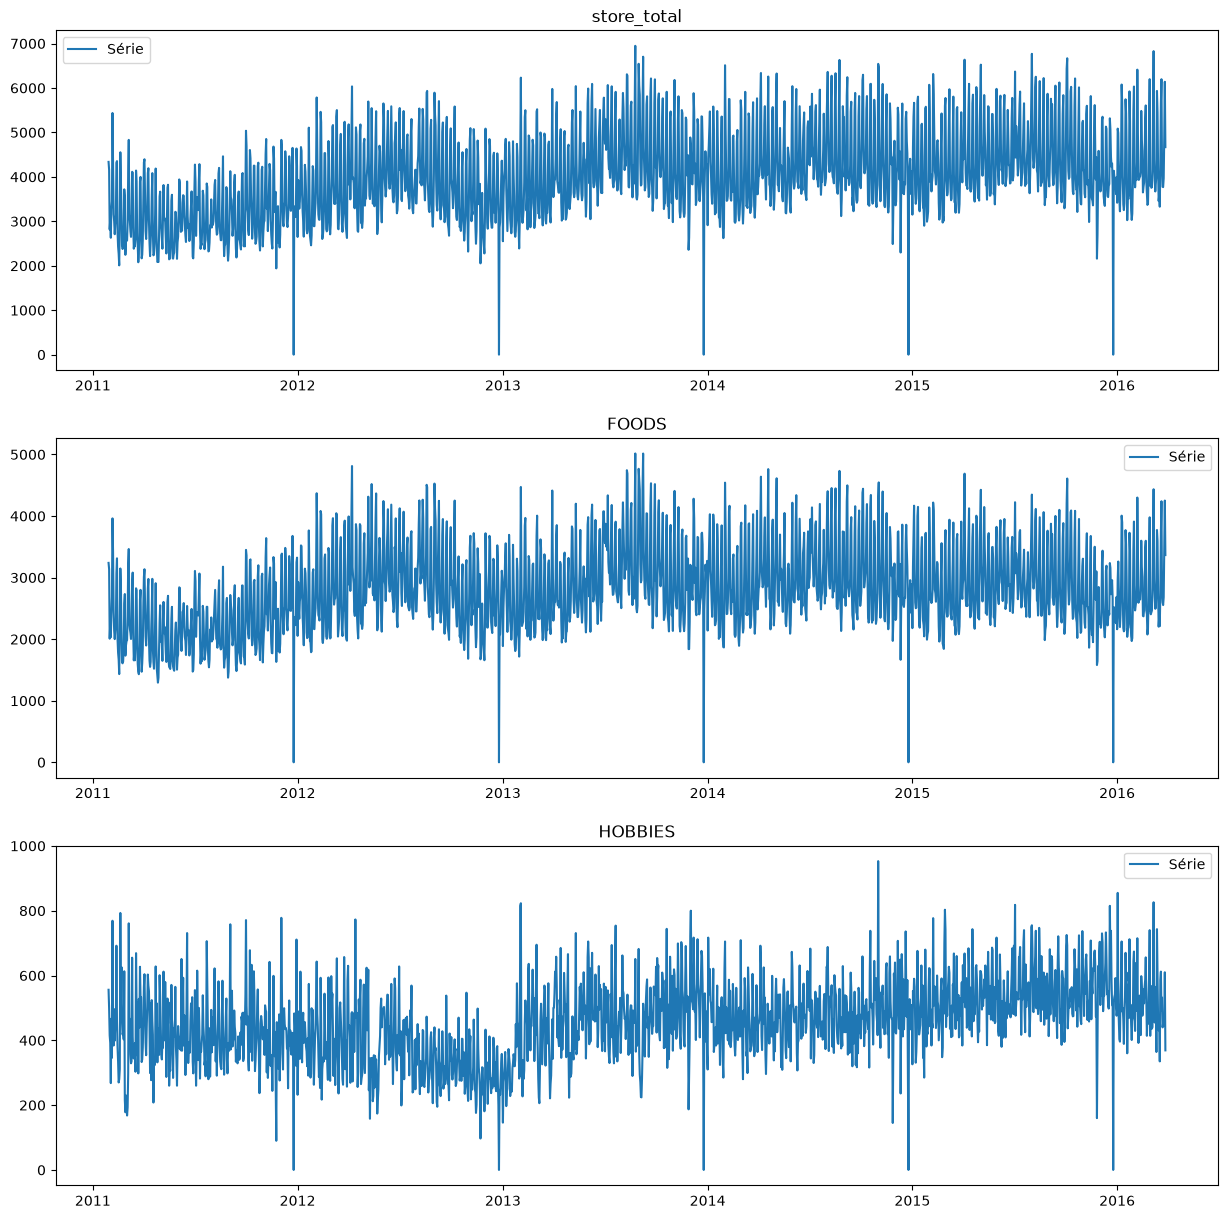

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total"], label="Série")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS"], label="Série")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES"], label="Série")
axes[2].set(title="HOBBIES")
axes[2].legend()


**Leitura das séries.** As três têm forte oscilação de curto prazo e um nível que cresce no começo do período. `store_total` e `FOODS` são quase proporcionais (alimentos são cerca de 70% das vendas da loja); `HOBBIES` é uma ordem de grandeza menor (≈ 460/dia, contra ≈ 4000 do total) e relativamente mais ruidosa. Há quedas isoladas até zero, uma por ano, tratadas na seção de outliers.

## Diagnóstico Visual de Tendência (Média Móvel)

In [4]:
window = 3*30

# Media movel do conjunto de treino
df_train["store_total_mean_movel"] = df_train['store_total'].rolling(window=window).mean().bfill()
df_train["FOODS_mean_movel"] = df_train['FOODS'].rolling(window=window).mean().bfill()
df_train["HOBBIES_mean_movel"] = df_train['HOBBIES'].rolling(window=window).mean().bfill()


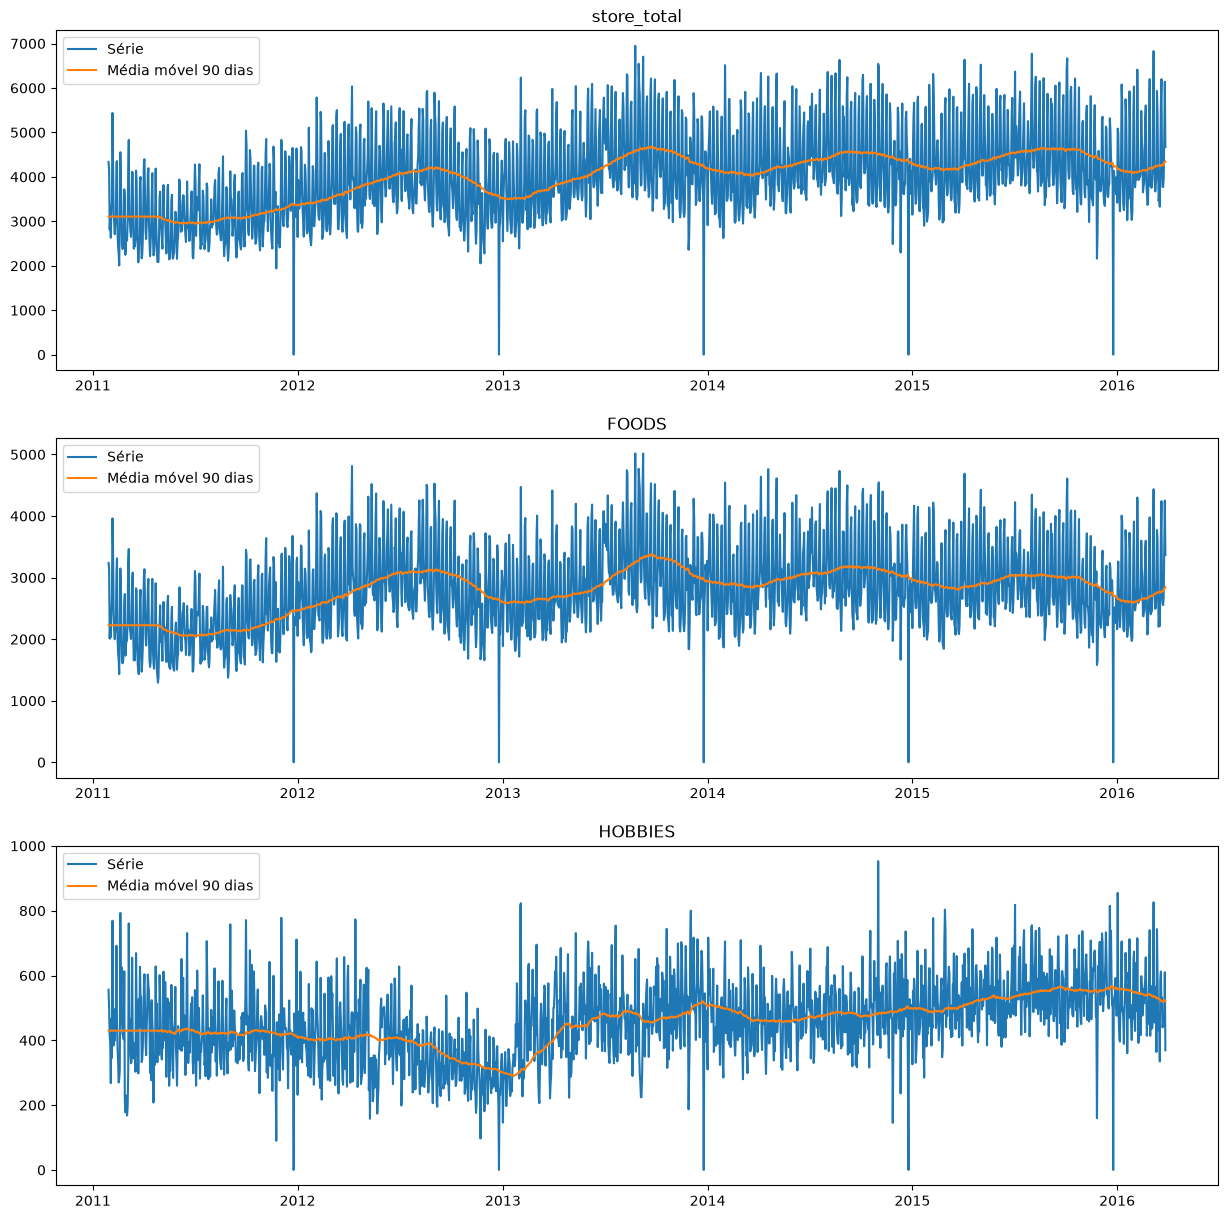

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total"], label="Série")
axes[0].plot(df_train["date"], df_train["store_total_mean_movel"], label=f"Média móvel {window} dias")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS"], label="Série")
axes[1].plot(df_train["date"], df_train["FOODS_mean_movel"], label=f"Média móvel {window} dias")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES"], label="Série")
axes[2].plot(df_train["date"], df_train["HOBBIES_mean_movel"], label=f"Média móvel {window} dias")
axes[2].set(title="HOBBIES")
axes[2].legend()

**Tendência.** A média móvel de 90 dias sobe de 2011 até 2013–2014 em `store_total` (de ≈ 3400 para ≈ 4300) e `FOODS` (de ≈ 2500 para ≈ 3000). Depois fica estável em `store_total` e oscila em `FOODS`. Em `HOBBIES` o nível cai em 2012 (≈ 300), volta a ≈ 500 em 2013 e fica entre 500 e 560 depois. A média móvel é calculada só no treino. O `bfill()` preenche apenas os primeiros 89 pontos, que não têm janela completa, e serve só para o gráfico.

*Consequência para a modelagem:* o nível não é constante, então a **média histórica** é um baseline fraco, e uma diferenciação (d=1) é candidata em `store_total` e `FOODS`.

## Análise de Sazonalidades

#### Overlay por período

In [6]:
def get_sazonalidade_overlay(
    df: pd.DataFrame, 
    group_col: str | list[str], 
    x_col: str | list[str], 
    y_col: str | list[str]
) -> pd.DataFrame:
    df_sazon = (
        df
        .pivot_table(values=y_col, index=x_col, columns=group_col, aggfunc='sum')
        # .reset_index()
    )
    
    return df_sazon

In [7]:
def plot_sazonalidade_overlay(
    df_sazon: pd.DataFrame,
    series: str | list[str], 
    legend_title: str
):
    s_qtt = len(series)
    fig, axes = plt.subplots(s_qtt, 1, figsize=(15, 5*s_qtt))
    axes = np.ravel([axes])
    
    # Faz o plot em cada uma das series
    for i, each_serie in enumerate(series):
        df_sazon[each_serie].plot(ax=axes[i], marker='.')
        axes[i].set(title=each_serie)
        axes[i].legend(title=legend_title, bbox_to_anchor=(1.1, 1), loc="upper right")

In [8]:
train_sazon_trimester = get_sazonalidade_overlay(df=df_train, group_col="year", x_col="trimester", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_month     = get_sazonalidade_overlay(df=df_train, group_col="year", x_col="month", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_week      = get_sazonalidade_overlay(df=df_train, group_col="month", x_col="week", y_col=["store_total", "FOODS", "HOBBIES"])
train_sazon_weekday   = get_sazonalidade_overlay(df=df_train, group_col="week", x_col="weekday", y_col=["store_total", "FOODS", "HOBBIES"])

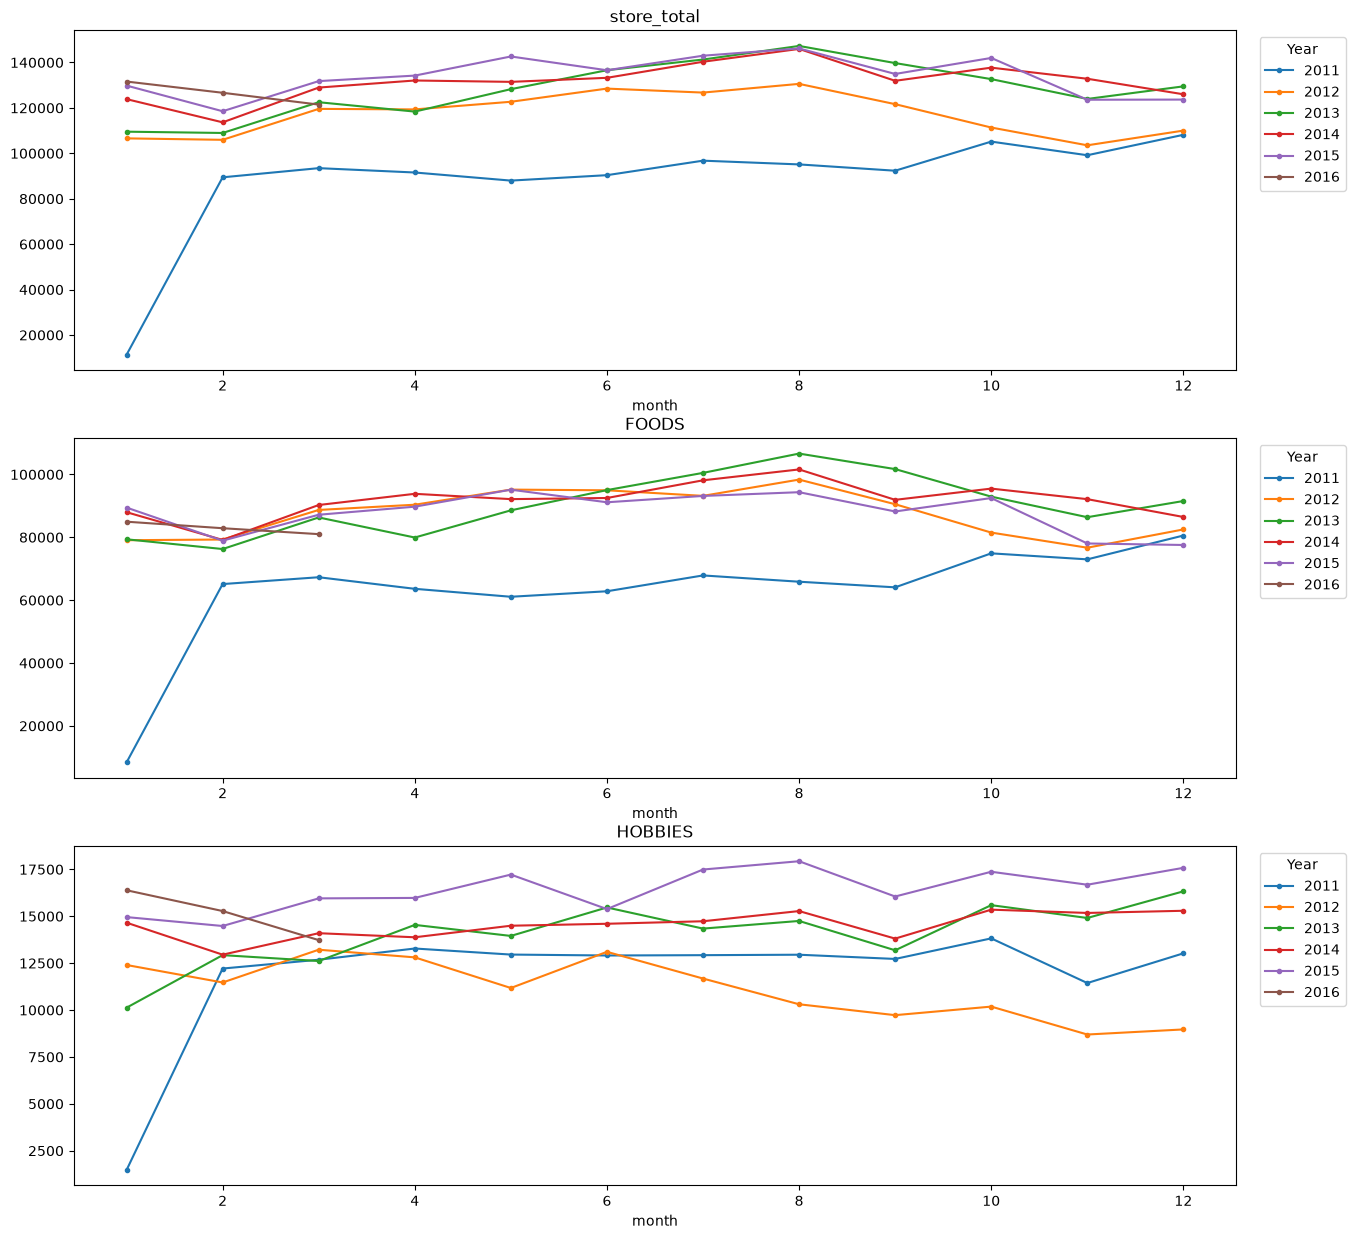

In [9]:
plot_sazonalidade_overlay(df_sazon=train_sazon_month, series=["store_total", "FOODS", "HOBBIES"], legend_title="Year")

**Sazonalidade anual/mensal.** O total mensal tem padrão fraco e instável: costuma subir de março a agosto e cair entre outubro e fevereiro, mas o formato muda de um ano para outro. O ponto de janeiro/2011 é artificialmente baixo porque o treino começa em 29/01 (mês incompleto), e os pontos de 2016 cobrem só janeiro a março. Com pouco mais de 5 anos e um padrão tão irregular, não faz sentido modelar sazonalidade anual aqui; o horizonte é de 28 dias, onde o que domina é o ciclo semanal.

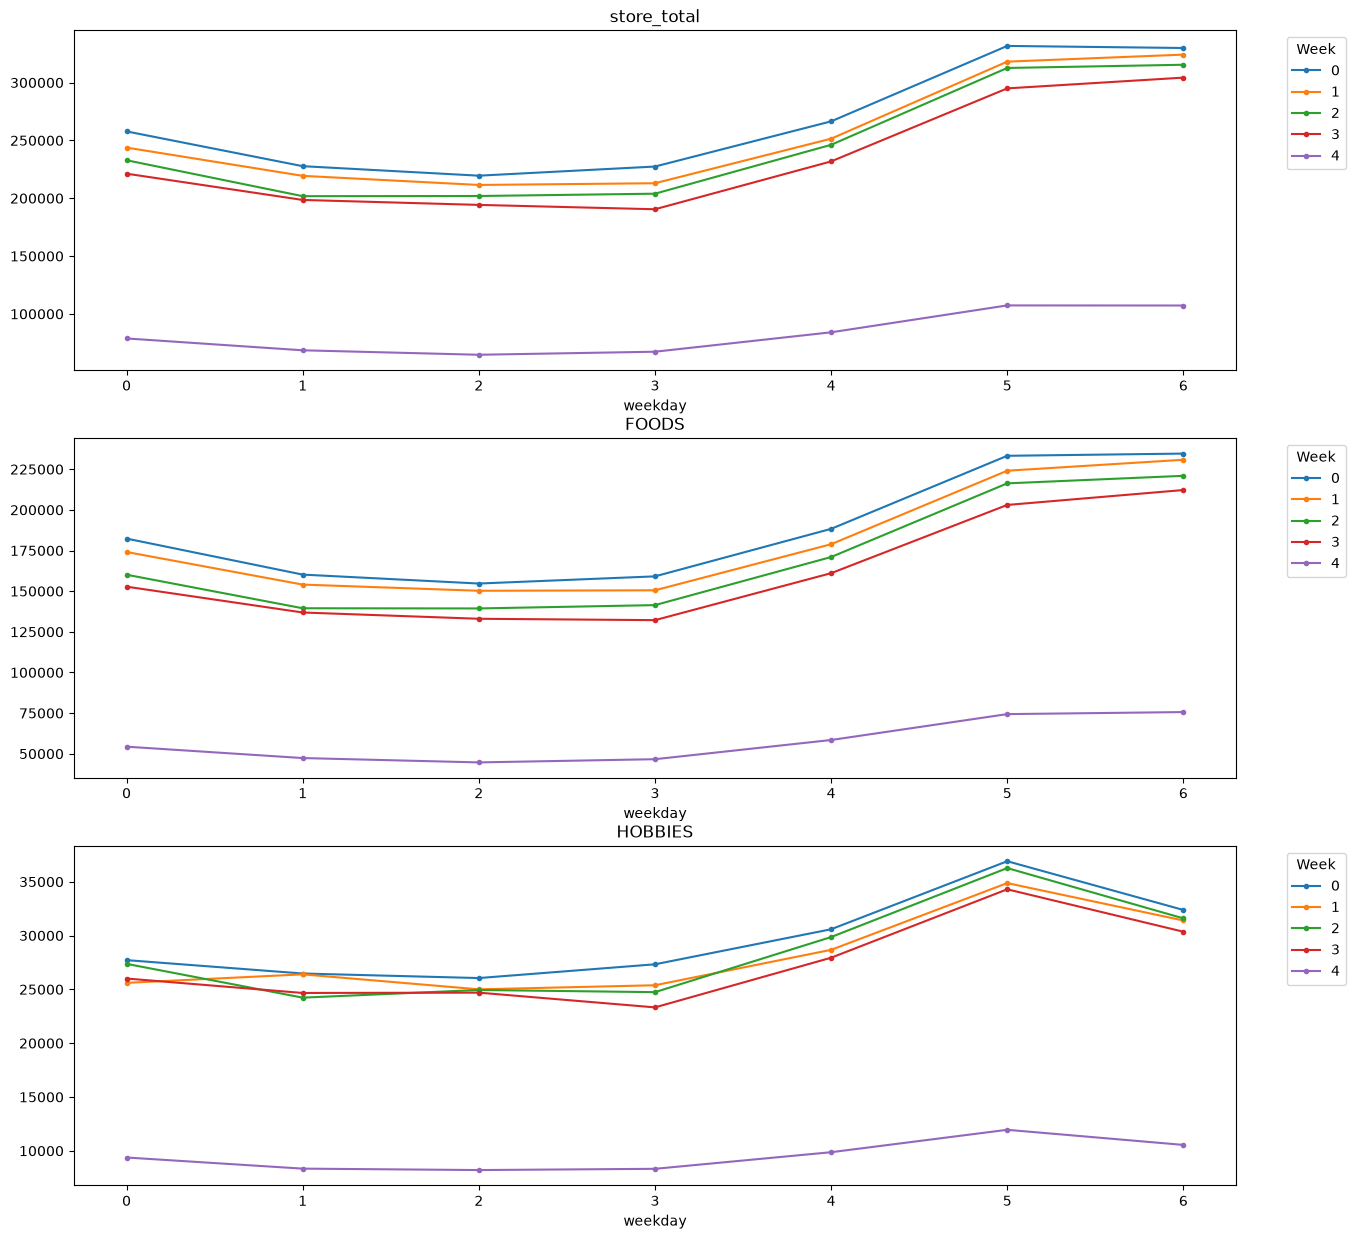

In [10]:
plot_sazonalidade_overlay(df_sazon=train_sazon_weekday, series=["store_total", "FOODS", "HOBBIES"], legend_title="Week")

#### Série sem Tendência:

In [11]:
series = ["store_total", "FOODS", "HOBBIES"]

# Cria as colunas de series sem tendencia
for each_serie in series:
    df_train[f"{each_serie}_without_trend"] = df_train[each_serie] - df_train[f"{each_serie}_mean_movel"]

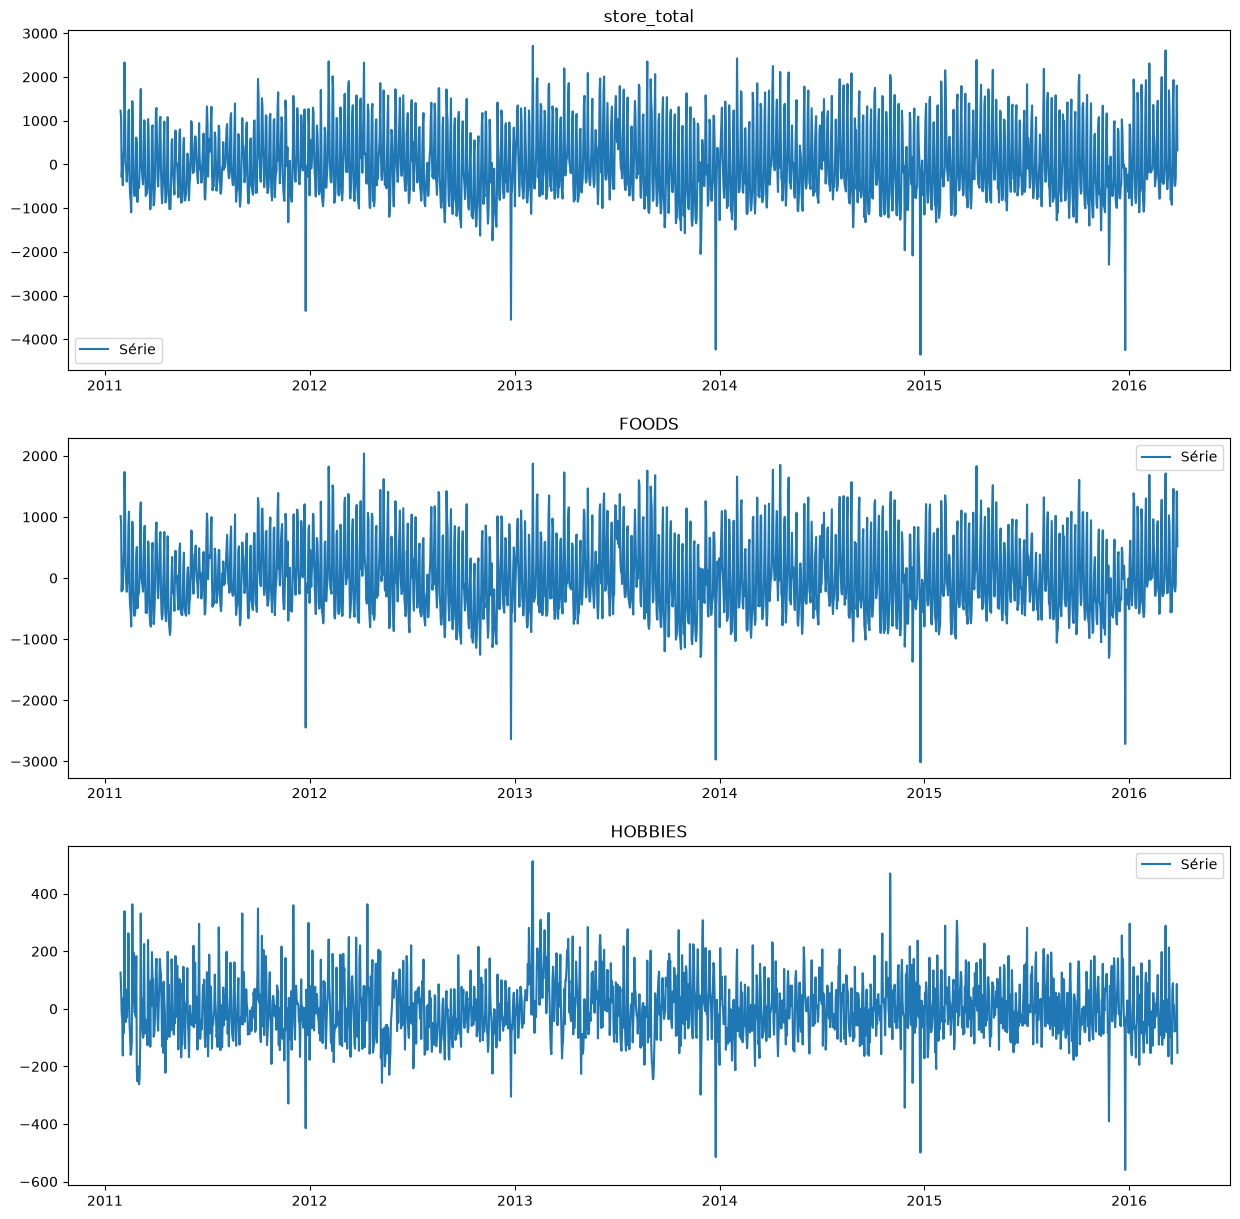

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total_without_trend"], label="Série")
axes[0].set(title="store_total")
axes[0].legend()

axes[1].plot(df_train["date"], df_train["FOODS_without_trend"], label="Série")
axes[1].set(title="FOODS")
axes[1].legend()

axes[2].plot(df_train["date"], df_train["HOBBIES_without_trend"], label="Série")
axes[2].set(title="HOBBIES")
axes[2].legend()


Série menos a média móvel (tendência removida): o nível fica centrado em zero e o padrão de oscilação regular fica evidente. Os picos para baixo no fim de cada dezembro continuam visíveis.

#### Boxplot por fase do período

In [13]:
def plot_sazonalidade_boxplot(
    df: pd.DataFrame, 
    group_col: str | list[str], 
    y_col: str | list[str]
) -> pd.DataFrame:
    y_col = np.ravel([y_col])
    fig, axes = plt.subplots(y_col.size, 1, figsize=(15, 5*y_col.size))
    axes = np.ravel([axes])
    for ax, each_y in zip(axes, y_col):
        df.boxplot(column=each_y, by=group_col, ax=ax)
        ax.grid(False)

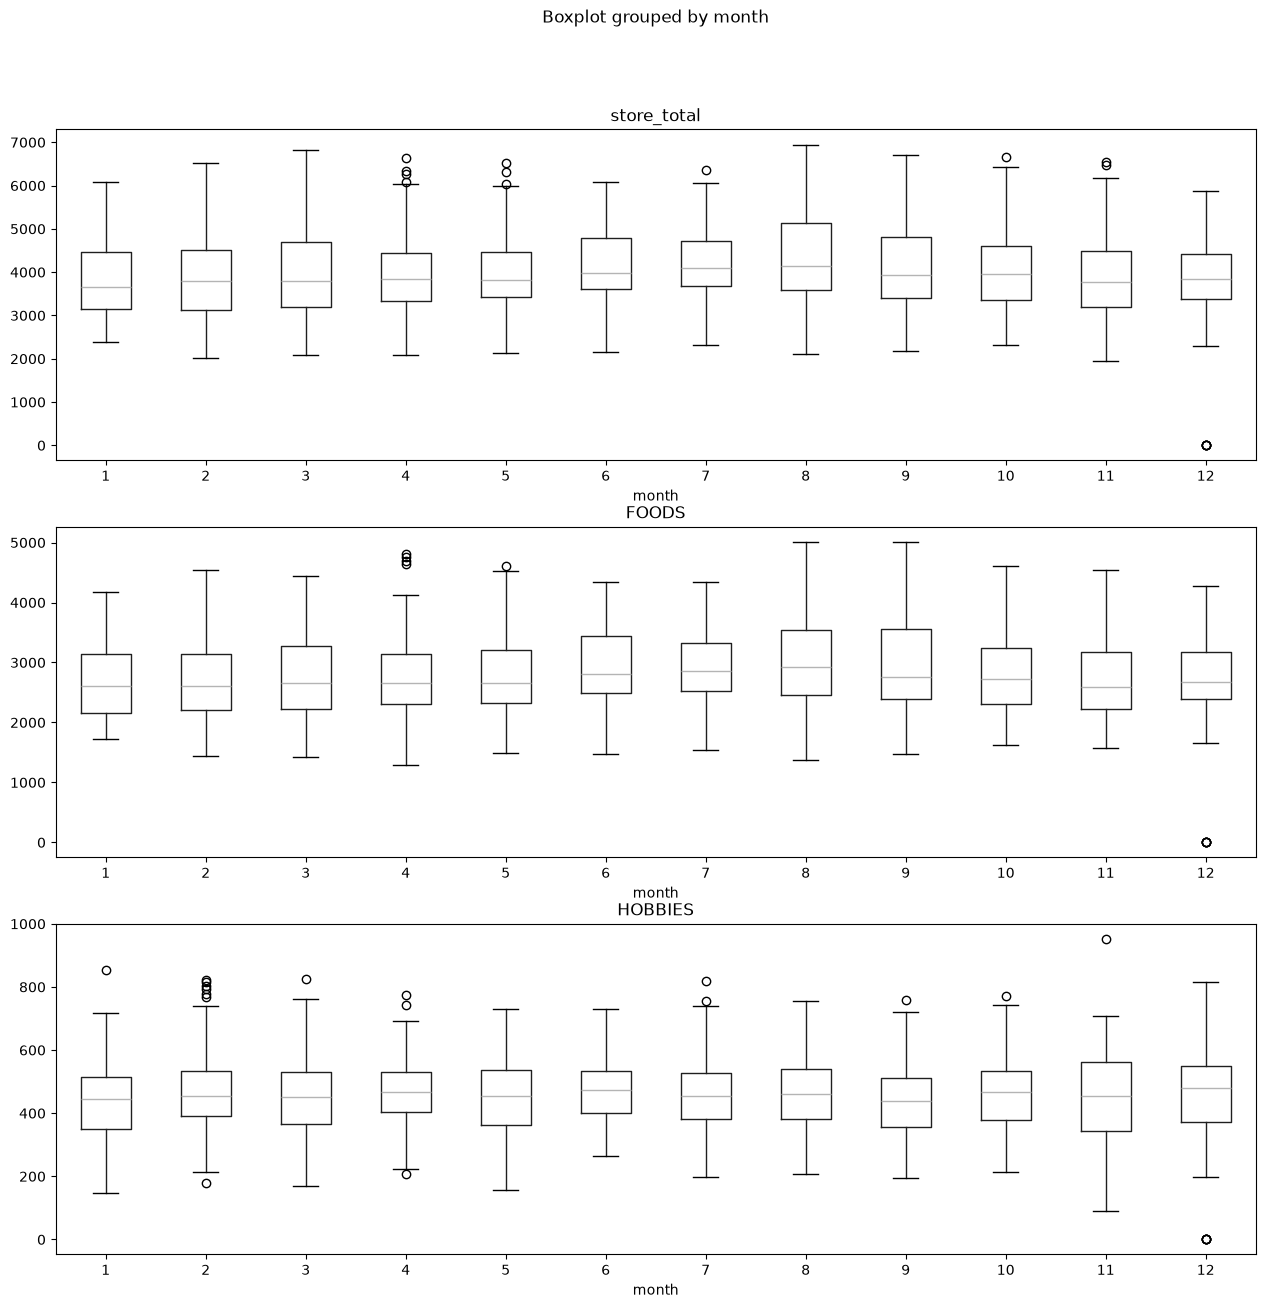

In [14]:
plot_sazonalidade_boxplot(df=df_train, group_col="month", y_col=series)

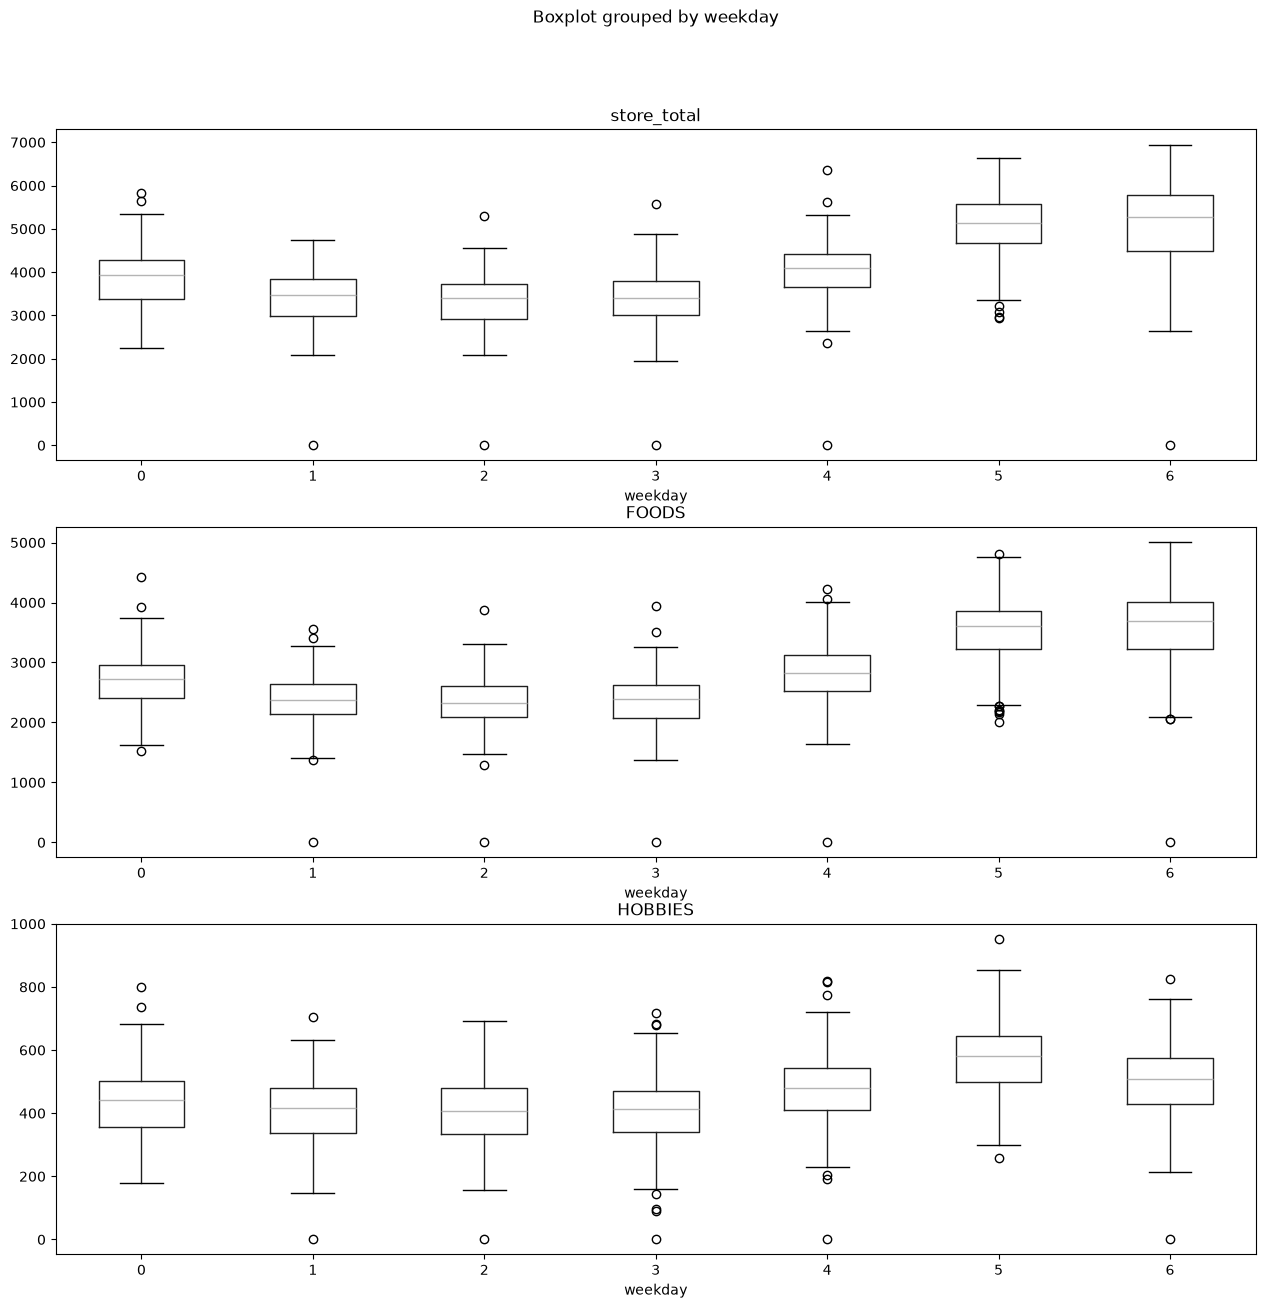

In [15]:
plot_sazonalidade_boxplot(df=df_train, group_col="weekday", y_col=series)

**Sazonalidade semanal (m = 7).** O boxplot por dia da semana (0 = segunda, 6 = domingo) mostra o padrão mais forte do conjunto: **sábado e domingo vendem mais** (mediana de `store_total` ≈ 5200 contra ≈ 3400 de terça a quinta), a segunda-feira é intermediária e sexta já sobe. As caixas de sábado/domingo e as de terça a quinta não se sobrepõem. O padrão é parecido em `FOODS` e mais fraco em `HOBBIES`, onde a diferença entre sábado e dias úteis é de ≈ 170 unidades sobre uma base de ≈ 410.

*Consequência:* período sazonal m = 7. O naive sazonal e o SARIMA com sazonalidade semanal devem ganhar muito de modelos que ignoram o dia da semana (`naive`, `drift`, `média`).

#### Estimativa para a Sazonalidade (Média Semanal das Séries sem Tendência)

In [16]:
estimativa_sazonalidade = (
    df_train
    .groupby("week_of_year")[[f"{s}_without_trend" for s in series]].mean()
    .rename(columns={f"{col}_without_trend": f"{col}_week_mean" for col in series})
    .reset_index()
)

[Text(0.5, 1.0, 'HOBBIES_Week_Year'), Text(0.5, 0, 'Week of Year')]

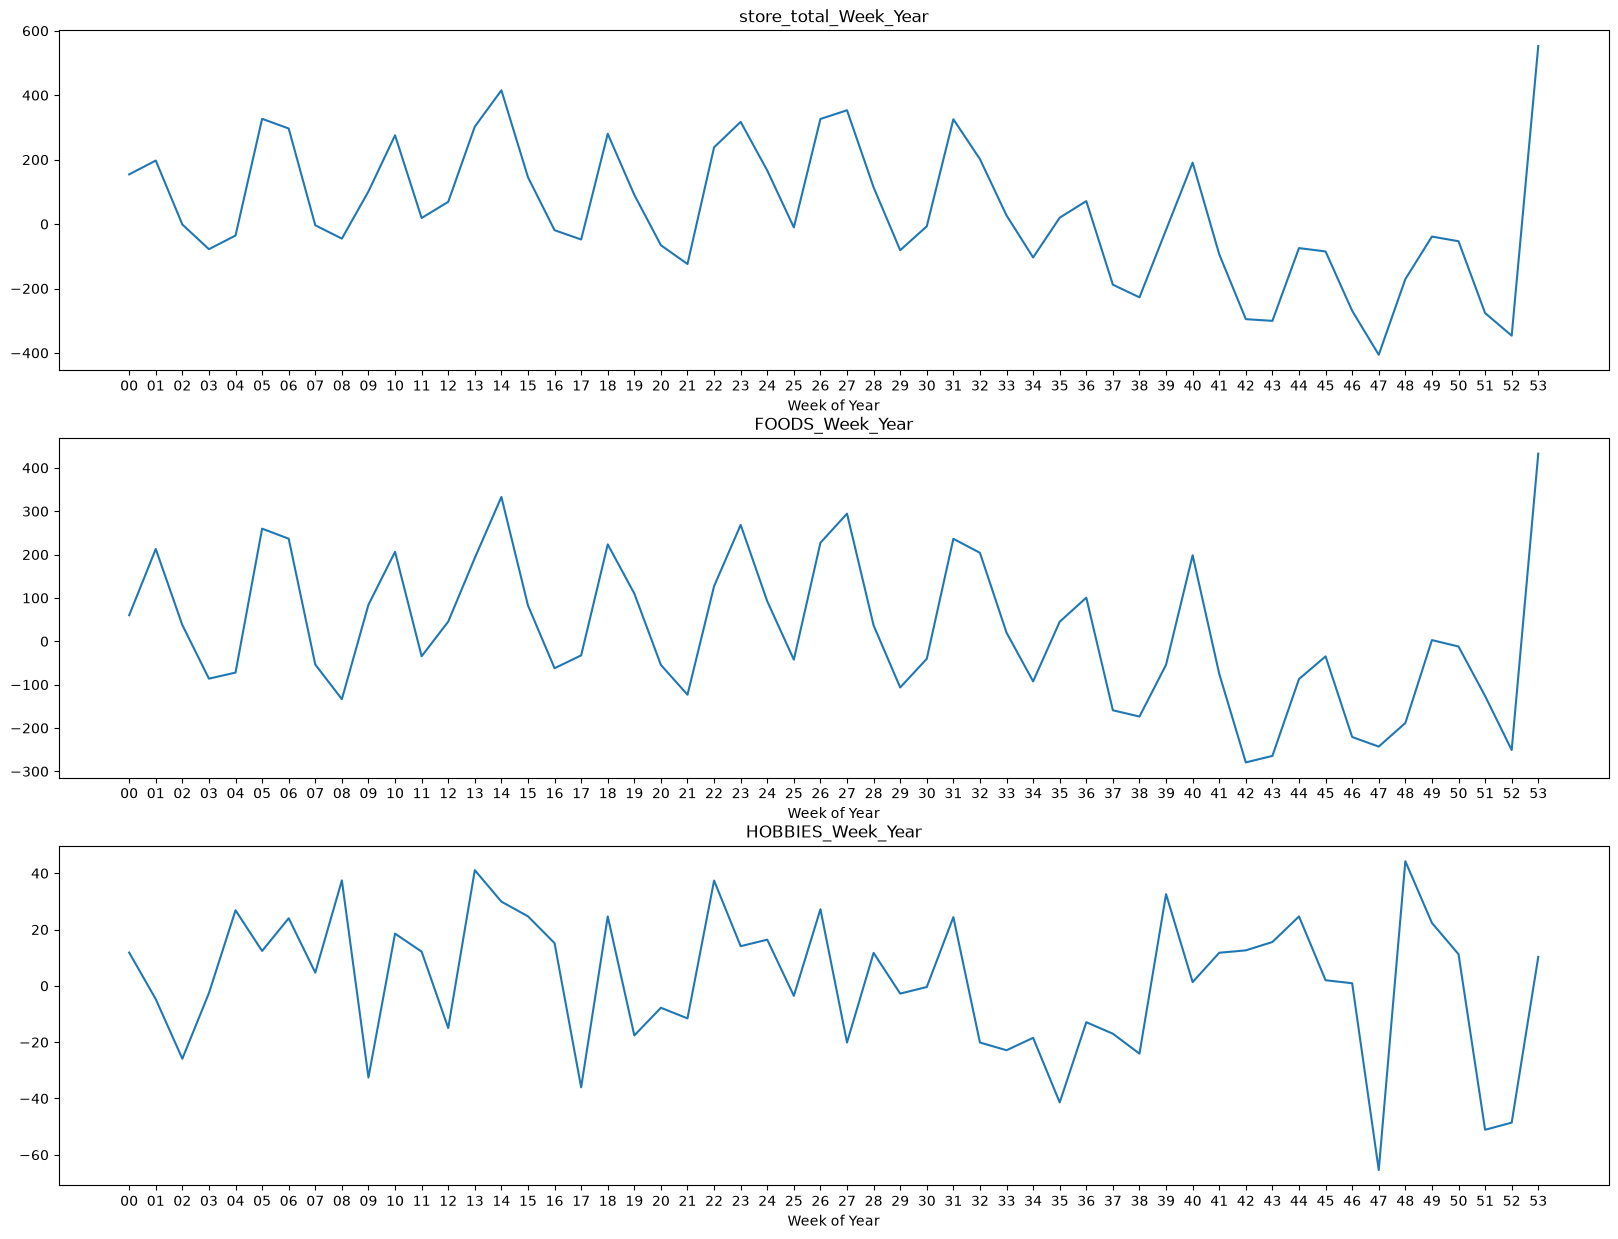

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(20, 15))
axes = np.ravel(axes)
axes[0].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["store_total_week_mean"])
axes[0].set(title="store_total_Week_Year", xlabel="Week of Year")

axes[1].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["FOODS_week_mean"])
axes[1].set(title="FOODS_Week_Year", xlabel="Week of Year")

axes[2].plot(estimativa_sazonalidade["week_of_year"], estimativa_sazonalidade["HOBBIES_week_mean"])
axes[2].set(title="HOBBIES_Week_Year", xlabel="Week of Year")


In [18]:
df_train = df_train.merge(estimativa_sazonalidade, on="week_of_year", how="left").sort_values("date")
for each_serie in series:
    df_train[f"{each_serie}_residuo"] = df_train[f"{each_serie}_without_trend"] - df_train[f"{each_serie}_week_mean"]

[Text(0.5, 1.0, 'HOBBIES_Residuo'), Text(0.5, 0, 'date')]

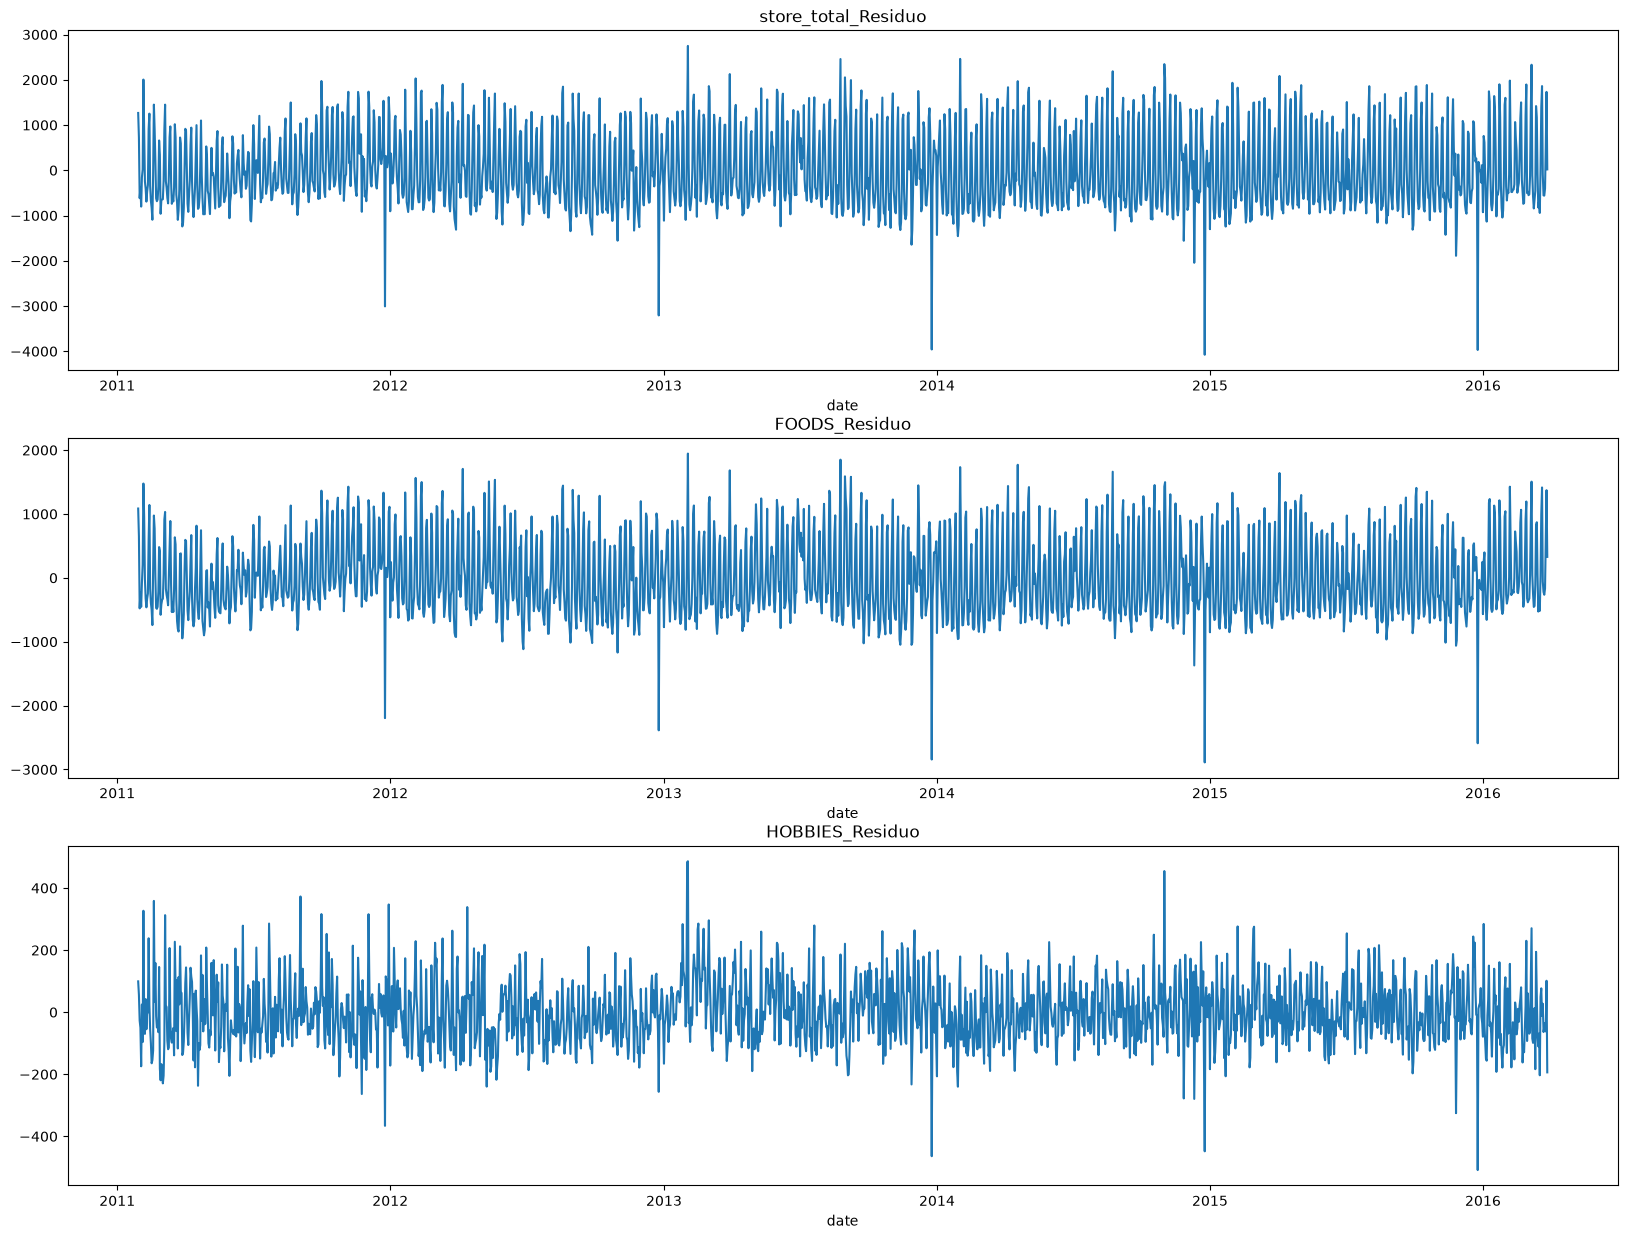

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(20, 15))
axes = np.ravel(axes)
axes[0].plot(df_train["date"], df_train["store_total_residuo"])
axes[0].set(title="store_total_Residuo", xlabel="date")

axes[1].plot(df_train["date"], df_train["FOODS_residuo"])
axes[1].set(title="FOODS_Residuo", xlabel="date")

axes[2].plot(df_train["date"], df_train["HOBBIES_residuo"])
axes[2].set(title="HOBBIES_Residuo", xlabel="date")

**Resíduo da decomposição simples** (série − tendência − média por semana do ano). Esta estimativa agrupa por semana do ano, não por dia da semana, então **não remove o ciclo semanal**: o resíduo continua com a mesma oscilação regular, sem tendência aparente e com variância razoavelmente estável. O que se destaca são as quedas isoladas de fim de dezembro (≈ −3000 a −4000 em `store_total`). Isso confirma que a sazonalidade relevante é a semanal.

#### Funções Estatísticas

In [20]:
def acvf_amostral(serie: pd.Series, h: int):
    T              = serie.size
    serie          = np.asarray(serie).astype(float)
    desvios        = (serie - serie.mean())
    desvios_Y_t_h  = desvios[h:]
    desvios_Y_t    = desvios[:T-h]
    # Calcula a ACVF amostral de h
    return np.dot(desvios_Y_t_h, desvios_Y_t) / T


def acf(serie: pd.Series, h: int):
    if h == 0: return 1.0
    # Calcula a ACVF amostral de h e de 0
    cov_h = acvf_amostral(serie=serie, h=h)
    cov_0 = acvf_amostral(serie=serie, h=0)
    
    return float(cov_h / cov_0)

In [21]:
def levinson_durbin_pacf(serie: pd.Series, max_lag: int):
    # Calcula a ACF global para todos os lags de 0 ate max_lag
    mean = serie.mean()
    var = serie.var(ddof=0)
    
    if var == 0:
        return np.zeros(max_lag + 1)
        
    y = serie.values - mean
    
    # Vetor de autocorrelacoes rho de 0 ate max_lag
    rho = np.zeros(max_lag + 1)
    rho[0] = 1.0
    for h in range(1, max_lag + 1):
        cov_h = np.mean(y[:-h] * y[h:])
        rho[h] = cov_h / var

    # Inicializacao do Levinson-Durbin (Lag 1)
    pacf = np.zeros(max_lag + 1)
    pacf[0] = 1.0
    
    if max_lag == 0:
        return pacf

    # Para lag 1
    phi_prev = np.array([rho[1]])
    pacf[1] = rho[1]
    v = 1.0 - rho[1]**2

    # Loop de recursao para k = 2 ate max_lag
    for k in range(2, max_lag + 1):
        # Calcula phi_{k,k} (PACF no lag k)
        numerador = rho[k] - np.dot(phi_prev, rho[1:k][::-1])
        phi_kk = numerador / v
        
        pacf[k] = phi_kk
        
        # Atualiza os coeficientes anteriores (phi_{k, j})
        phi_curr = np.zeros(k)
        phi_curr[:-1] = phi_prev - phi_kk * phi_prev[::-1]
        phi_curr[-1] = phi_kk
        
        # Atualiza a variancia do erro v_k
        v = v * (1.0 - phi_kk**2)
        
        # Prepara para a proxima iteração
        phi_prev = phi_curr

    return pacf

In [22]:
def compute_serie_autocorrel(df: pd.DataFrame, serie: str, max_lag: int):
    lags = np.arange(max_lag+1)
    acfs = np.array([
        acf(serie=df[serie], h=h) 
        for h in lags
    ])
    pacfs = levinson_durbin_pacf(serie=df[serie], max_lag=max_lag)
    return lags, acfs, pacfs

In [23]:
def plot_acf_pacf(lags, acfs, banda_acf: np.array, pacfs, banda_pacf: np.array, serie_name: str, axes=None):
    if axes is None:
        fig, axes = plt.subplots(2, 1, figsize=(10, 8))
        
    axes[0].hlines(0, xmin=lags.min(), xmax=lags.max(), ls='-', color="gray")
    axes[0].axhspan(-banda_acf.max(), banda_acf.max(), color='gray', alpha=0.3, label='$\\pm 1.96 / \\sqrt{T}$')
    axes[0].plot(lags, banda_acf, alpha=0.3, color="gray")
    axes[0].plot(lags, -banda_acf, alpha=0.3, color="gray")
    axes[0].vlines(x=lags, ymin=np.zeros_like(lags), ymax=acfs)
    axes[0].scatter(lags, acfs, marker=".")
    axes[0].set(
        xlim=(-0.2, lags.max()+0.2),
        ylim=(-1.1, 1.1),
        title=f"{serie_name} ACF"
    )
    axes[0].legend()

    axes[1].hlines(0, xmin=lags.min(), xmax=lags.max(), ls='-', color="gray")
    axes[1].axhspan(-banda_pacf.max(), banda_pacf.max(), color='gray', alpha=0.3, label='$\\pm 1.96 / \\sqrt{T}$')
    axes[1].plot(lags, banda_pacf, alpha=0.3, color="gray")
    axes[1].plot(lags, -banda_pacf, alpha=0.3, color="gray")
    axes[1].vlines(x=lags, ymin=np.zeros_like(lags), ymax=pacfs)
    axes[1].scatter(lags, pacfs, marker=".")
    axes[1].set(
        xlim=(-0.2, lags.max()+0.2),
        ylim=(-1.1, 1.1),
        title=f"{serie_name} PACF"
    )
    axes[1].legend()

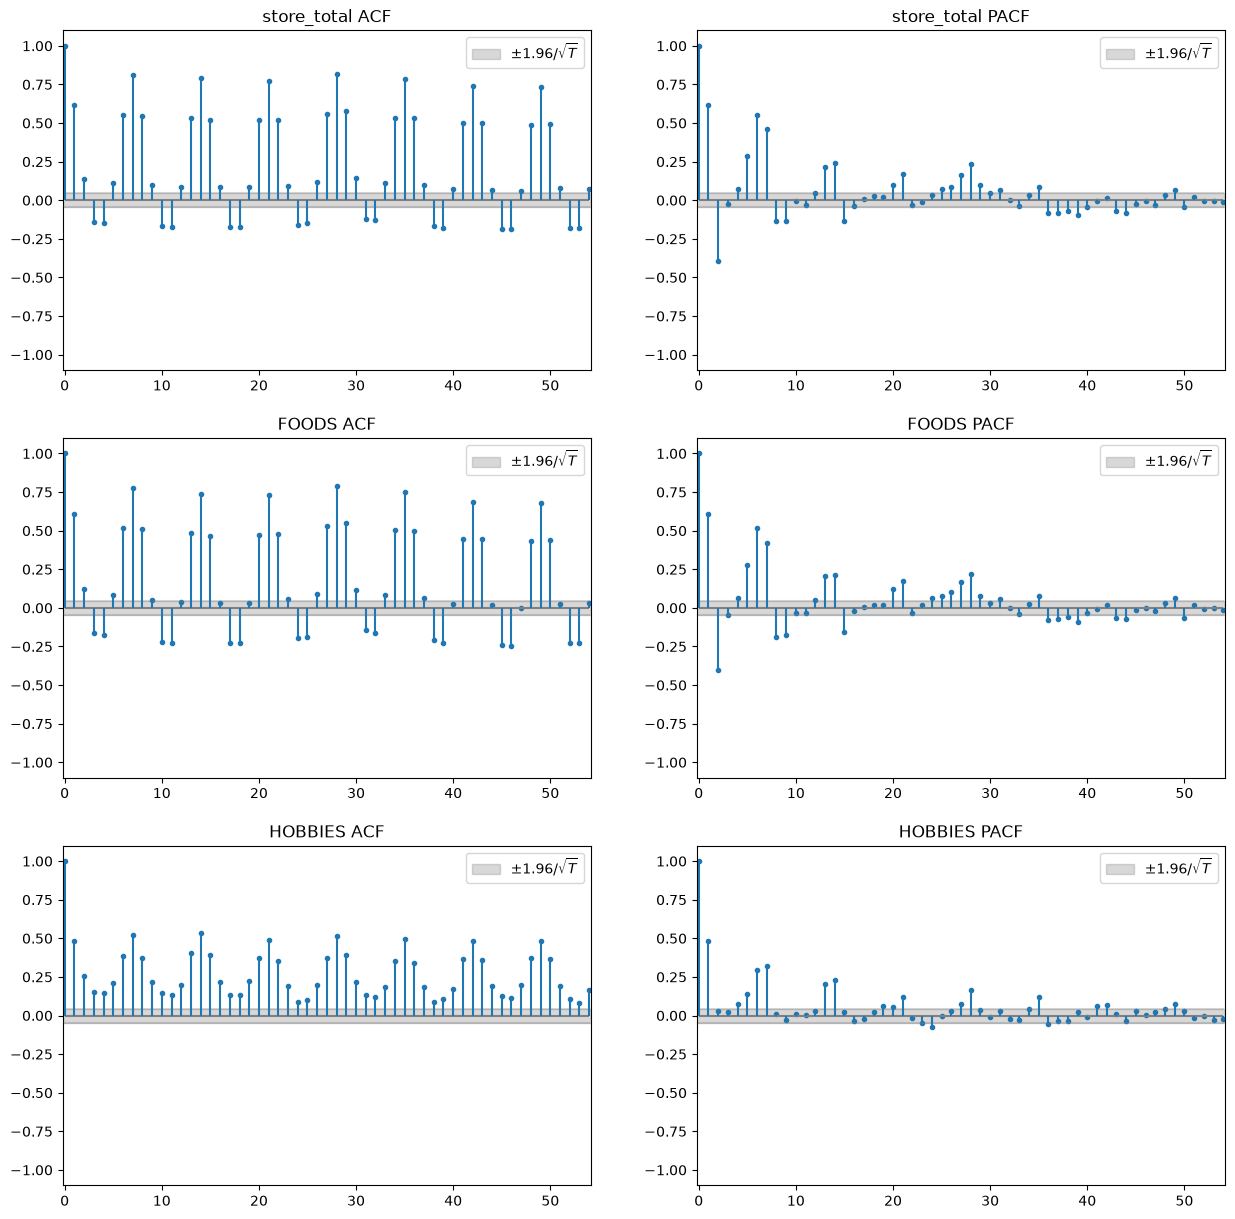

In [24]:
max_lag = 54
lags, acfs_store_total, pacfs_store_total = compute_serie_autocorrel(df=df_train, serie="store_total", max_lag=max_lag)
lags, acfs_FOODS, pacfs_FOODS = compute_serie_autocorrel(df=df_train, serie="FOODS", max_lag=max_lag)
lags, acfs_HOBBIES, pacfs_HOBBIES = compute_serie_autocorrel(df=df_train, serie="HOBBIES", max_lag=max_lag)
banda_pacf = banda_acf = np.full_like(acfs_store_total, 1.96 / np.sqrt(len(df_train)))

fig, axes = plt.subplots(len(series), 2, figsize=(15, 5*len(series)))
axes = np.ravel(axes)
plot_acf_pacf(lags, acfs_store_total, banda_acf, pacfs_store_total, banda_pacf, axes=axes[:2], serie_name="store_total")
plot_acf_pacf(lags, acfs_FOODS, banda_acf, pacfs_FOODS, banda_pacf, axes=axes[2:4], serie_name="FOODS")
plot_acf_pacf(lags, acfs_HOBBIES, banda_acf, pacfs_HOBBIES, banda_pacf, axes=axes[4:], serie_name="HOBBIES")

**ACF/PACF das séries originais (treino).** O ACF é fortemente periódico: picos em 7, 14, 21, 28... (≈ 0,8 em `store_total` e `FOODS`, ≈ 0,5 em `HOBBIES`), alternando com vales negativos entre os picos. Isso é a assinatura de sazonalidade semanal determinística e de não estacionariedade em nível. O PACF é significativo nos lags 1–7 e ainda em múltiplos de 7. A banda cinza é ±1,96/√T.

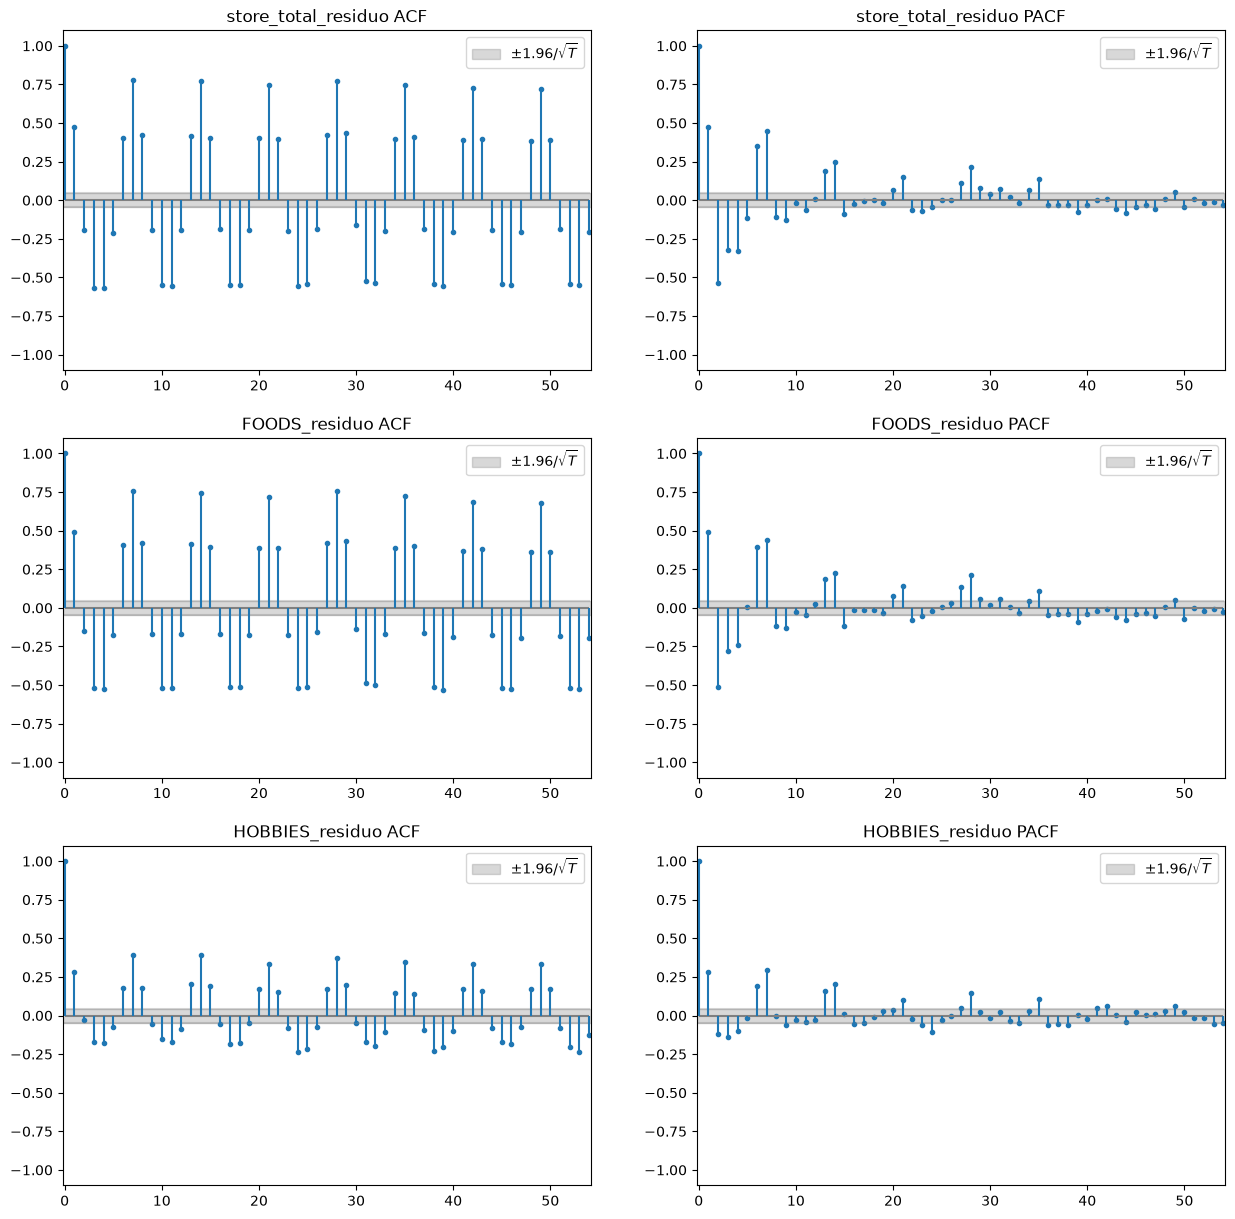

In [25]:
max_lag = 54
lags, acfs_store_total_residuo, pacfs_store_total_residuo = compute_serie_autocorrel(df=df_train, serie="store_total_residuo", max_lag=max_lag)
lags, acfs_FOODS_residuo, pacfs_FOODS_residuo = compute_serie_autocorrel(df=df_train, serie="FOODS_residuo", max_lag=max_lag)
lags, acfs_HOBBIES_residuo, pacfs_HOBBIES_residuo = compute_serie_autocorrel(df=df_train, serie="HOBBIES_residuo", max_lag=max_lag)
banda_pacf = banda_acf = np.full_like(acfs_store_total_residuo, 1.96 / np.sqrt(len(df_train)))

fig, axes = plt.subplots(len(series), 2, figsize=(15, 5*len(series)))
axes = np.ravel(axes)
plot_acf_pacf(lags, acfs_store_total_residuo, banda_acf, pacfs_store_total_residuo, banda_pacf, axes=axes[:2], serie_name="store_total_residuo")
plot_acf_pacf(lags, acfs_FOODS_residuo, banda_acf, pacfs_FOODS_residuo, banda_pacf, axes=axes[2:4], serie_name="FOODS_residuo")
plot_acf_pacf(lags, acfs_HOBBIES_residuo, banda_acf, pacfs_HOBBIES_residuo, banda_pacf, axes=axes[4:], serie_name="HOBBIES_residuo")

**ACF/PACF do resíduo.** Mesmo depois de remover a tendência, o ACF do resíduo mantém os picos em múltiplos de 7 quase com a mesma altura. Isto indica que a **diferenciação sazonal (D=1, m=7)** é necessária no SARIMA. Na Parte 3 o ACF/PACF é recalculado depois de diff(1) e diff sazonal(7), onde a estrutura se resume a poucos termos MA/AR.

### Outliers e zeros de calendário

In [26]:
series = ["store_total", "FOODS", "HOBBIES"]
zeros = df_train[df_train[series].eq(0).any(axis=1)][["date"] + series]
print(f"Dias com venda zero no treino: {len(zeros)}")
zeros

Dias com venda zero no treino: 5


,date,store_total,FOODS,HOBBIES
330,2011-12-25,0,0,0
696,2012-12-25,0,0,0
1061,2013-12-25,0,0,0
1426,2014-12-25,0,0,0
1791,2015-12-25,0,0,0


Os zeros caem sempre em **25 de dezembro** (loja fechada), um por ano, e valem para as três séries ao mesmo tempo. São eventos de calendário, não erro de medição. Decisão: **manter no treino**. Remover ou imputar exigiria um critério que o enunciado não pede, e os 28 dias de validação (março-abril) não contêm Natal. O efeito é aumentar um pouco o ruído estimado do SARIMA e entrar na escala do MASE (que é um MAE in-sample).

Além dos zeros, os boxplots mostram outliers moderados nas pontas (por exemplo, sábados baixos), sem padrão sistemático.

### Testes de raiz unitária (treino)

In [27]:
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

linhas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # kpss avisa quando o p-valor sai da tabela
    for s in series:
        y = df_train[s].astype(float)
        linhas.append({
            "serie": s,
            "ADF p (nível)": adfuller(y, autolag="AIC")[1],
            "KPSS p (nível)": kpss(y, regression="c", nlags="auto")[1],
            "ADF p (após diff sazonal 7)": adfuller(y.diff(7).dropna(), autolag="AIC")[1],
        })
pd.DataFrame(linhas).round(4)

,serie,ADF p (nível),KPSS p (nível),ADF p (após diff sazonal 7)
0,store_total,0.2509,0.01,0.0
1,FOODS,0.1449,0.01,0.0
2,HOBBIES,0.0354,0.01,0.0


ADF tem H0 = raiz unitária; KPSS tem H0 = estacionariedade. Em `store_total` (p ≈ 0,25) e `FOODS` (p ≈ 0,14) o ADF **não rejeita** raiz unitária no nível, e o KPSS rejeita estacionariedade nas três (p ≈ 0,01, limite inferior da tabela). Em `HOBBIES` o ADF rejeita a 5% (p ≈ 0,035), então a necessidade de d=1 é menos clara. Depois da diferença sazonal de lag 7 o ADF rejeita raiz unitária com folga nas três séries. Conclusão prática: D=1 com m=7 em todas, d=1 em `store_total` e `FOODS`, e d ∈ {0, 1} a decidir por AIC em `HOBBIES`.

### Conclusões do diagnóstico

| Aspecto | `store_total` | `FOODS` | `HOBBIES` |
|---|---|---|---|
| Tendência (média móvel 90d) | alta até 2013–2014, depois estável | alta até 2013–2014, depois oscila | queda em 2012, recuperação em 2013, depois estável |
| Sazonalidade semanal (m=7) | forte (fim de semana ≫ dias úteis) | forte | presente, mais fraca |
| Sazonalidade anual | fraca e irregular | fraca e irregular | fraca e irregular |
| Zeros / outliers | 5 zeros (25/12) | 5 zeros (25/12) | 5 zeros (25/12) |
| Raiz unitária (ADF no nível) | não rejeita | não rejeita | rejeita a 5% (limítrofe) |

**O que isso significa para a Task:** (i) usar m=7 em todos os modelos sazonais; (ii) esperar que `naive`, `drift` e `média` percam para modelos com sazonalidade semanal; (iii) SARIMA com D=1, m=7 e d=1 como ponto de partida; (iv) tratar os zeros de Natal como conhecidos e fora do horizonte de validação; (v) não modelar sazonalidade anual, pois o horizonte é de 28 dias e o padrão anual é fraco e instável.

# Parte 2 — Baselines

Quatro baselines da aula, ajustados **só no treino** e avaliados nos 28 dias de validação. A implementação está em `src/ts_utils.py`, a mesma usada pelo `run.py`.

- **média:** média histórica do treino.
- **naive:** último valor do treino.
- **naive sazonal (m=7):** repete a última semana do treino.
- **drift:** reta entre a primeira e a última observação do treino.

Cada baseline usa só `y_train`; a validação serve apenas para calcular o erro.

### Previsões e métricas

MASE com escala = MAE in-sample do naive sazonal (m=7) no treino.

In [28]:
linhas = []
prev = {}
for s in SERIES:
    y_tr, y_va = treino[s].to_numpy(float), val[s].to_numpy(float)
    prev[s] = calcular_baselines(y_tr, h=h, m=M)
    for modelo, yhat in prev[s].items():
        mae, rmse, mase = calcular_metricas(y_tr, y_va, yhat)
        linhas.append({"series": s, "modelo": modelo, "mae": mae, "rmse": rmse, "mase": mase})
metricas_baselines = pd.DataFrame(linhas)
metricas_baselines.round(3)

,series,modelo,mae,rmse,mase
0,store_total,media,813.885,1109.595,1.871
1,store_total,naive,862.750,966.632,1.983
2,store_total,naive_sazonal,459.179,655.467,1.056
3,store_total,drift,863.279,966.756,1.984
4,FOODS,media,526.929,671.830,1.540
5,FOODS,naive,664.643,722.859,1.943
6,FOODS,naive_sazonal,343.857,420.116,1.005
7,FOODS,drift,664.965,723.257,1.944
8,HOBBIES,media,110.995,141.305,1.216
9,HOBBIES,naive,169.036,204.728,1.851


### Conferência com o `metricas.csv` oficial

In [29]:
oficial = pd.read_csv(RAIZ / "metricas.csv")
oficial = oficial[oficial.modelo.isin(BASELINES)].reset_index(drop=True)
assert np.allclose(oficial[["mae", "rmse", "mase"]], metricas_baselines[["mae", "rmse", "mase"]])
print("OK: baselines do notebook = baselines de metricas.csv")

OK: baselines do notebook = baselines de metricas.csv


### Gráfico

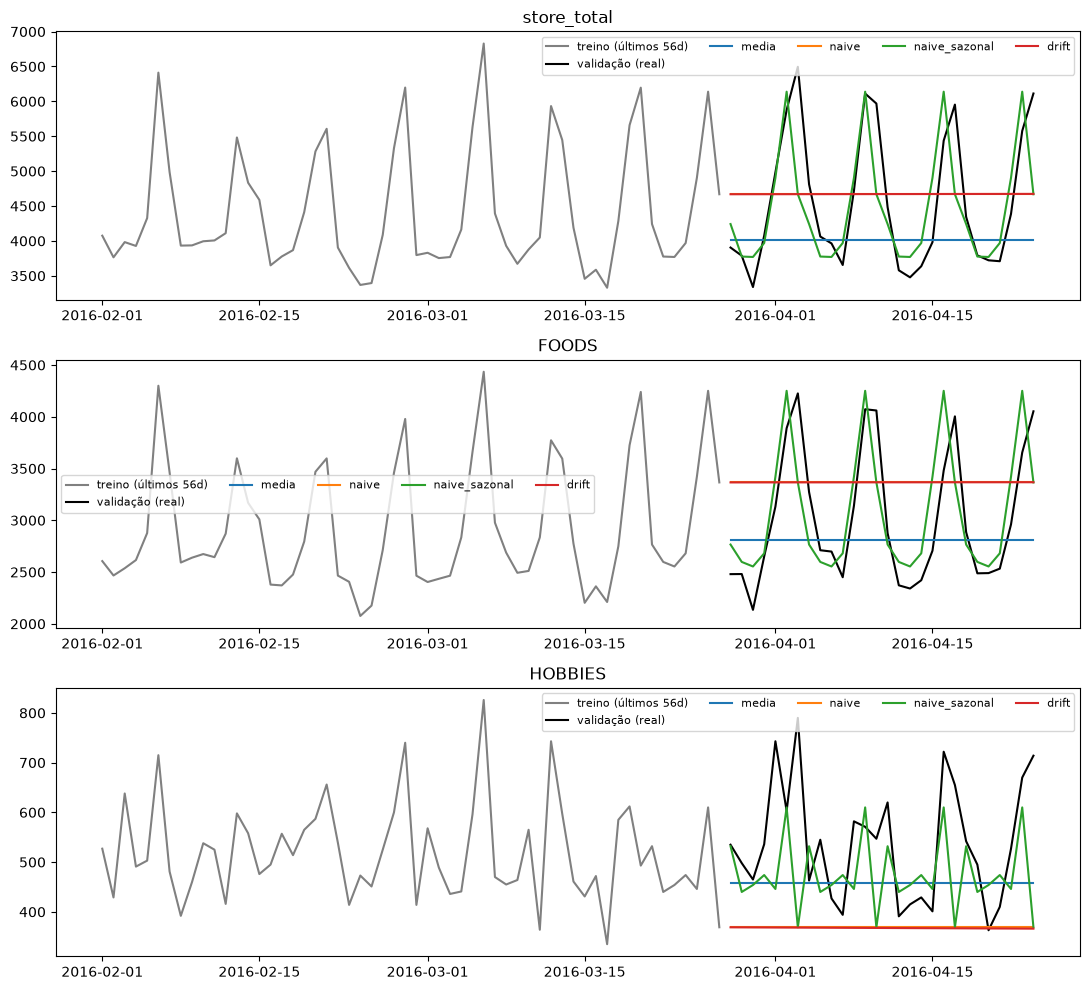

In [30]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
for a, s in zip(ax, SERIES):
    a.plot(treino.date.tail(56), treino[s].tail(56), color="gray", label="treino (últimos 56d)")
    a.plot(val.date, val[s], color="black", label="validação (real)")
    for modelo, yhat in prev[s].items():
        a.plot(val.date, yhat, label=modelo)
    a.set_title(s); a.legend(ncol=5, fontsize=8)
fig.tight_layout()

### Leitura

`naive` e `drift` ignoram a sazonalidade semanal e ficam com MASE ≈ 1,9–2,0 nas três séries; o drift é quase idêntico ao naive porque a inclinação do treino é minúscula. A média perde para o naive sazonal em `store_total` e `FOODS`; em `HOBBIES` o naive sazonal tem MAE menor e a média tem RMSE menor, e ambos têm MASE > 1. A comparação com o SARIMA está na Parte 3.

# Parte 3 — ARIMA/SARIMA: identificação, ajuste e previsão

Identificação e ajuste usam só o `treino`. A validação entra depois, em `calcular_metricas`, para avaliar as previsões já geradas. A ordem **não** é escolhida pelo erro na validação. O código de identificação e ajuste é o do `run.py` (importado), então este notebook reproduz o `metricas.csv`.

### 1. Identificação

**Estacionariedade e diferenciação.** O ACF das três séries tem picos em 7, 14, 21, 28 (sazonalidade semanal forte), então D=1 com m=7. O ADF no nível não rejeita raiz unitária em `store_total` e `FOODS`; em `HOBBIES` é limítrofe (ver o teste na Parte 1). Abaixo, ACF/PACF após diff(1) e diff sazonal(7).

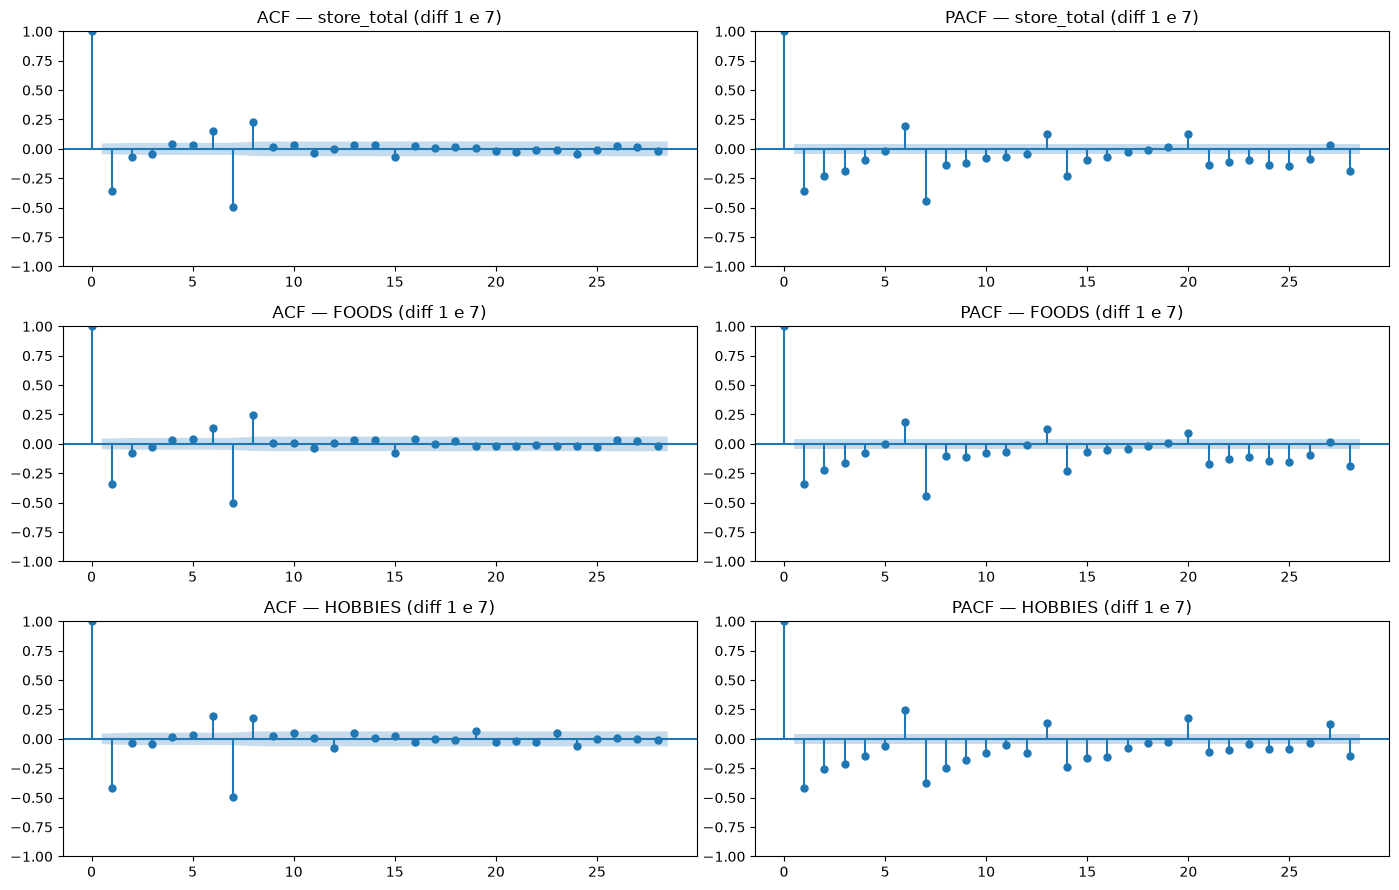

In [31]:
fig, ax = plt.subplots(3, 2, figsize=(14, 9))
for i, s in enumerate(SERIES):
    dif = treino.set_index("date")[s].diff().diff(M).dropna().to_numpy()
    plot_acf(dif, lags=28, ax=ax[i, 0], title=f"ACF — {s} (diff 1 e 7)")
    plot_pacf(dif, lags=28, ax=ax[i, 1], method="ywm", title=f"PACF — {s} (diff 1 e 7)")
fig.tight_layout()

**Leitura.** Em todas as séries o ACF diferenciado tem pico negativo no lag 1 (−0,34 a −0,42) e no lag 7 (≈ −0,5): estrutura MA(1) × MA sazonal(1), o "airline model" (0,1,1)(0,1,1)₇ como ponto de partida. O PACF decai devagar, o que deixa espaço para termos AR. Isso restringe a grade a p,q ≤ 2, P,Q ≤ 1, d ∈ {0,1}, D=1; dentro dela escolhe-se o menor AIC (72 modelos por série).

**Por que AIC e não o erro de validação?** Escolher a ordem pela validação seria vazamento (a validação viraria parte do ajuste e a métrica ficaria otimista). O AIC é calculado só no treino. Cuidados: (i) o 2º colocado fica a apenas 0,1 ponto de AIC do escolhido em `store_total`, 2,6 em `FOODS` e 1,6 em `HOBBIES` (top 3 abaixo), então a escolha entre os primeiros não é conclusiva; (ii) comparar AIC entre d=0 e d=1 é delicado porque a diferenciação muda a amostra efetiva, por isso a escolha de d em `HOBBIES` é a menos firme; (iii) os modelos usam as restrições padrão de estacionariedade/invertibilidade do `SARIMAX`, e só entram na disputa os ajustes que convergem.

In [32]:
ordens, resultados = {}, {}
for s in SERIES:
    y = treino[s].to_numpy(float)
    ordem, sazonal, aic, bic, _ = run.identificar_sarima(y, s)
    ordens[s] = (ordem, sazonal)
    print(f"  -> escolhida: SARIMA{ordem}{sazonal}  AIC={aic:.1f}\n")

  store_total: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=28143.93
    SARIMA(2, 1, 2)(1, 1, 1, 7)  AIC=28144.04
    SARIMA(1, 1, 1)(1, 1, 1, 7)  AIC=28144.27
  -> escolhida: SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=28143.9



  FOODS: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=27051.50
    SARIMA(1, 1, 1)(1, 1, 1, 7)  AIC=27054.08
    SARIMA(2, 1, 2)(1, 1, 1, 7)  AIC=27059.40
  -> escolhida: SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=27051.5



  HOBBIES: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 0, 1)(0, 1, 1, 7)  AIC=22117.22
    SARIMA(2, 0, 1)(1, 1, 1, 7)  AIC=22118.83
    SARIMA(1, 0, 2)(0, 1, 1, 7)  AIC=22122.17
  -> escolhida: SARIMA(2, 0, 1)(0, 1, 1, 7)  AIC=22117.2



### Diagnóstico dos resíduos do ajuste final

O teste de Ljung-Box (H0: resíduos sem autocorrelação) é calculado nos lags 7, 14 e 28 sobre os resíduos do modelo ajustado **no treino**. Os primeiros 8 resíduos são descartados porque o filtro de Kalman ainda está inicializando com as diferenciações.

In [33]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ajustes = {}
tabela = []
for s in SERIES:
    y = treino[s].to_numpy(float)
    ajustes[s] = run.SARIMAX(y, order=ordens[s][0], seasonal_order=ordens[s][1]).fit(disp=False, maxiter=200)
    res = ajustes[s].resid[8:]
    lb = acorr_ljungbox(res, lags=[7, 14, 28])
    tabela.append({"series": s, **{f"LB p (lag {l})": p for l, p in zip(lb.index, lb["lb_pvalue"])}})
pd.DataFrame(tabela).round(4)

,series,LB p (lag 7),LB p (lag 14),LB p (lag 28)
0,store_total,0.9986,0.1189,0.0000
1,FOODS,0.9016,0.0019,0.0000
2,HOBBIES,0.5635,0.1444,0.0279


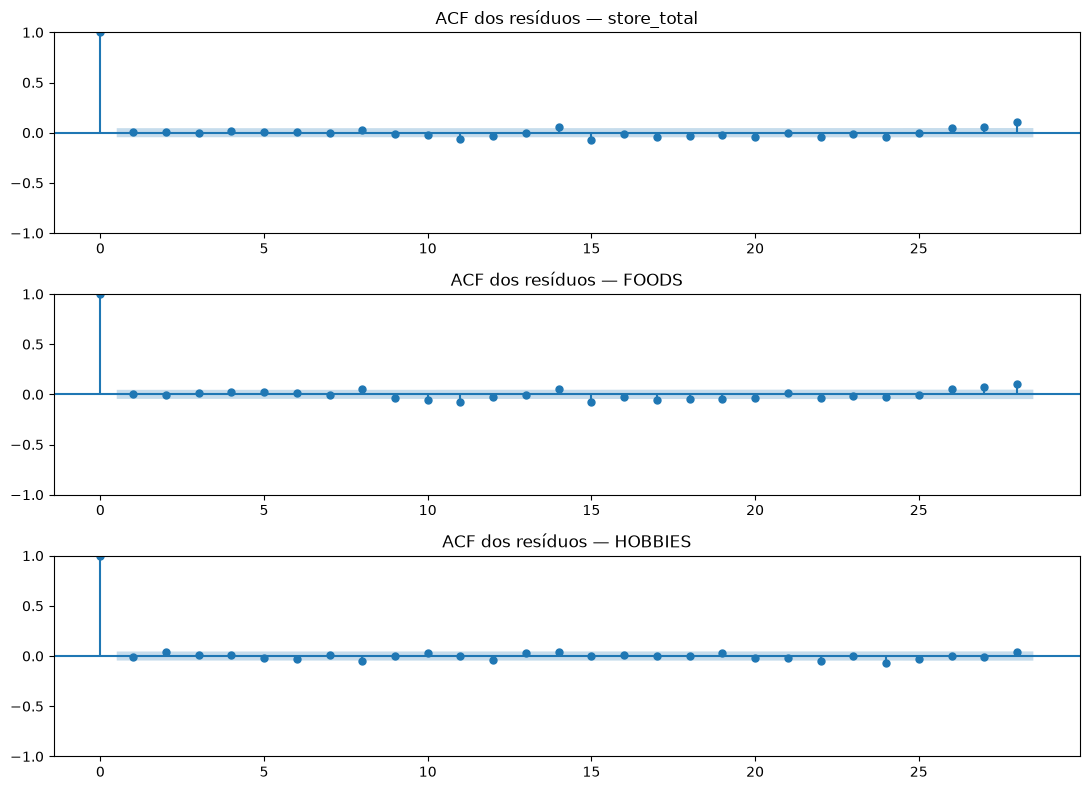

In [34]:
fig, ax = plt.subplots(3, 1, figsize=(11, 8))
for a, s in zip(ax, SERIES):
    plot_acf(ajustes[s].resid[8:], lags=28, ax=a, title=f"ACF dos resíduos — {s}")
fig.tight_layout()

**Leitura dos resíduos.** No lag 7 o Ljung-Box **não rejeita** nas três séries (p = 0,999, 0,90 e 0,56): o ciclo semanal foi bem capturado. No lag 14 só `FOODS` rejeita (p ≈ 0,002). No lag 28 as três rejeitam (p < 0,001 em `store_total` e `FOODS`; p ≈ 0,03 em `HOBBIES`). Ou seja, sobra alguma autocorrelação em lags mais longos. É plausível: os zeros de Natal são outliers grandes, e feriados e promoções móveis não são capturados por um SARIMA sem regressores (o enunciado não os exige). Isto limita a confiança nas previsões mais distantes do horizonte e fica registrado como limitação, sem alterar o modelo escolhido.

### 2. Previsão (28 dias) e métricas

In [35]:
prev_sarima, linhas = {}, []
for s in SERIES:
    y_tr, y_va = treino[s].to_numpy(float), val[s].to_numpy(float)
    prev_sarima[s] = run.prever_sarima(y_tr, *ordens[s], h)
    mae, rmse, mase = calcular_metricas(y_tr, y_va, prev_sarima[s])
    linhas.append({"series": s, "modelo": "sarima", "ordem": f"{ordens[s][0]}{ordens[s][1]}", "mae": mae, "rmse": rmse, "mase": mase})
metricas_sarima = pd.DataFrame(linhas)
metricas_sarima.round(3)

,series,modelo,ordem,mae,rmse,mase
0,store_total,sarima,"(2, 1, 1)(1, 1, 1, 7)",276.869,363.834,0.636
1,FOODS,sarima,"(2, 1, 1)(1, 1, 1, 7)",186.076,231.547,0.544
2,HOBBIES,sarima,"(2, 0, 1)(0, 1, 1, 7)",75.726,95.194,0.829


### 3. Conferência com o `metricas.csv` oficial e comparação com os baselines

In [36]:
oficial = pd.read_csv(RAIZ / "metricas.csv")
ref = oficial[oficial.modelo == "sarima"].reset_index(drop=True)
assert np.allclose(ref[["mae", "rmse", "mase"]], metricas_sarima[["mae", "rmse", "mase"]], rtol=1e-4)
print("OK: SARIMA do notebook = SARIMA de metricas.csv\n")
oficial.pivot(index="modelo", columns="series", values="mase").loc[BASELINES + ["sarima"]].round(2)

OK: SARIMA do notebook = SARIMA de metricas.csv



series,FOODS,HOBBIES,store_total
modelo,,,
media,1.54,1.22,1.87
naive,1.94,1.85,1.98
naive_sazonal,1.01,1.12,1.06
drift,1.94,1.87,1.98
sarima,0.54,0.83,0.64


**Conclusão.** O SARIMA tem o menor MAE, RMSE e MASE nas três séries (MASE < 1 em todas), isto é, melhora o naive sazonal in-sample usado como escala. O naive sazonal é o melhor baseline em `store_total` e `FOODS` (MASE ≈ 1,0); `naive` e `drift` ficam perto de 1,9–2,0 porque ignoram o ciclo semanal. Em `HOBBIES` o naive sazonal e a média têm MASE > 1 (pior que a escala), com resultado misto entre eles: naive sazonal ganha em MAE, média ganha em RMSE. O SARIMA não perde para nenhum baseline em nenhuma série, então não há caso a esconder.

**Limitações.** A validação tem só 28 dias (4 ciclos semanais) e um único corte temporal, sem backtesting em múltiplas origens nem intervalos de previsão. A margem do SARIMA sobre os baselines é grande, mas a ordem exata entre modelos próximos em `HOBBIES` não é garantida em outros períodos. Zeros de Natal e feriados móveis ficam sem tratamento explícito.

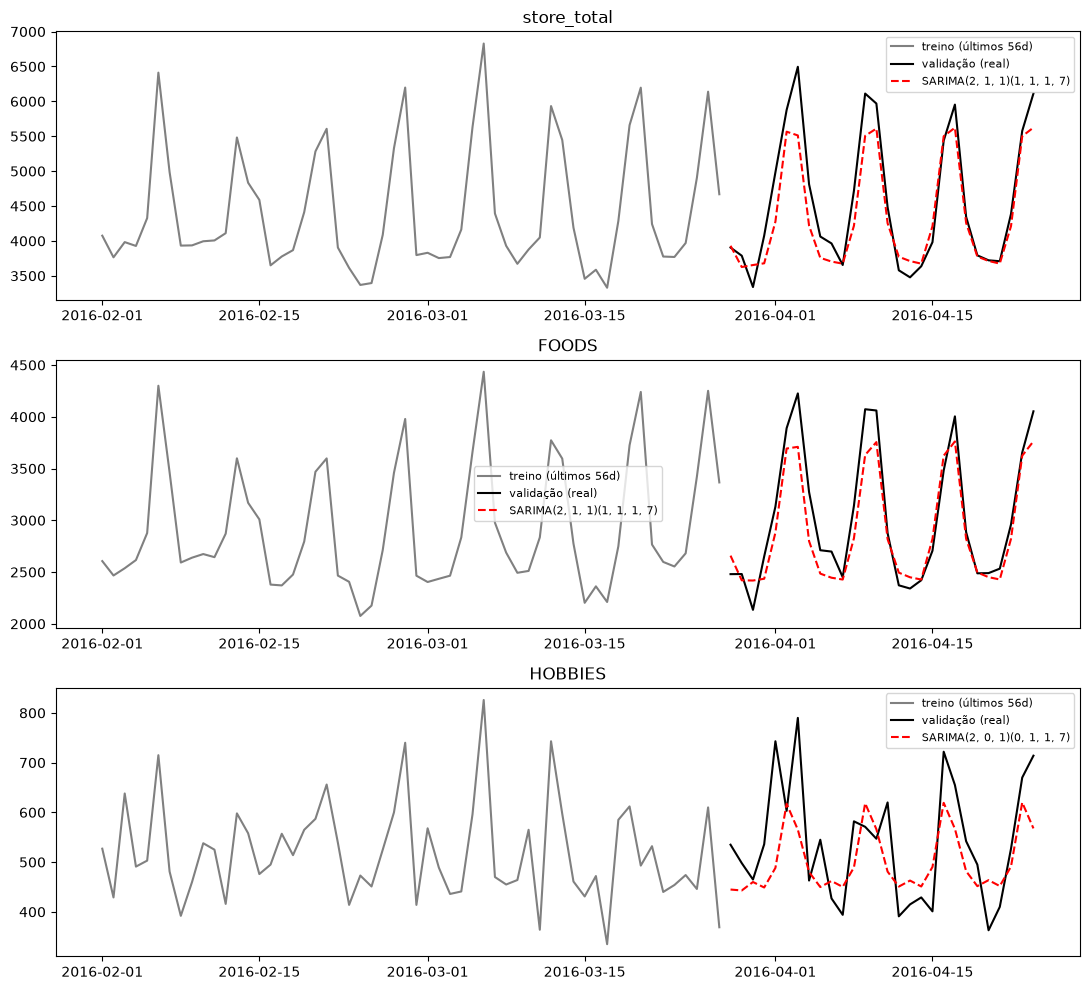

In [37]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
for a, s in zip(ax, SERIES):
    a.plot(treino.date.tail(56), treino[s].tail(56), color="gray", label="treino (últimos 56d)")
    a.plot(val.date, val[s], color="black", label="validação (real)")
    a.plot(val.date, prev_sarima[s], color="red", ls="--", label=f"SARIMA{ordens[s][0]}{ordens[s][1]}")
    a.set_title(s); a.legend(fontsize=8)
fig.tight_layout()